# SmartTour CyL · Lab 05a · Diseño del Data Warehouse de reservas

**Esquema en estrella para analizar reservas turísticas en Castilla y León: fuentes, hechos, dimensiones, justificación y consultas analíticas**

| | |
|---|---|
| **Proyecto** | SmartTour-BigData |
| **Cuaderno** | `02_Lab05a_Data_Warehouse.ipynb` |
| **Fecha** | 09/11/2026 |
| **Entorno** | Contenedor `smarttour-jupyter` (`quay.io/jupyter/datascience-notebook`) · pandas · matplotlib |
| **Datos** | `datasets/clean/*.csv` (fuentes limpias) y `datasets/dw/*.csv` (tablas del Data Warehouse) |

**Objetivo.** Resolver las actividades 1, 2, 3, 5 y 6 del Lab 05a. La actividad 4, el diagrama, está en [`docs/lab05a/diagrama.html`](../docs/lab05a/diagrama.html).

**Cómo leer este cuaderno.** Igual que en el análisis exploratorio, cada salida va seguida de una nota en un bloque de cita que explica qué significa.

**Sobre los datos.** Las tablas de `datasets/dw/` las genera `scripts/generate_dw.py` y son exactamente las que se cargan en el esquema `dw` de PostgreSQL. Aquí se leen con pandas para que el cuaderno funcione sin un driver de base de datos. Las consultas de la actividad 6 dan los mismos resultados que su versión SQL, en `sql/05_dw_queries.sql`.

## Índice

1. [Preparación](#setup)
2. [Actividad 1. Análisis de las fuentes de datos](#a1)
3. [Actividad 2. Hechos y dimensiones](#a2)
4. [Actividad 3. Esquema en estrella](#a3)
5. [Actividad 5. Justificación del diseño](#a5)
6. [Actividad 6. Consultas analíticas](#a6)
7. [Conclusiones](#summary)

<a id="setup"></a>
## 1. Preparación

Usa las mismas librerías, el mismo estilo de gráficos y las mismas utilidades que `01_EDA_Datasets.ipynb`:

| Utilidad | Para qué sirve |
|---|---|
| `fmt_es(n)` | Formatea números al estilo español (`2.248`, `47,1`) |
| `barh(serie, ...)` | Barras horizontales ordenadas, con su valor al lado de cada barra |
| `star()` | Une la tabla de hechos con sus cinco dimensiones: es el *star join* |

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

CLEAN_DIR = Path("../datasets/clean")
DW_DIR = Path("../datasets/dw")


def fmt_es(n, dec=0):
    """Formatea un número al estilo español: punto de miles y coma decimal."""
    return f"{n:,.{dec}f}".replace(",", "X").replace(".", ",").replace("X", ".")


pd.set_option("display.max_columns", 50)
pd.set_option("display.max_colwidth", 70)
pd.set_option("display.float_format", lambda x: fmt_es(x, 2))

ACCENT = "#2a78d6"        # serie principal
ACCENT_LIGHT = "#86b6ef"  # serie secundaria
NEUTRAL = "#c3c2b7"       # marcas sin énfasis
INK = "#0b0b0b"
INK_SECONDARY = "#52514e"
GRID = "#e6e5e0"
SURFACE = "#fcfcfb"

plt.rcParams.update({
    "figure.facecolor": SURFACE,
    "axes.facecolor": SURFACE,
    "axes.edgecolor": GRID,
    "axes.labelcolor": INK_SECONDARY,
    "axes.titlesize": 13,
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "text.color": INK,
    "xtick.color": INK_SECONDARY,
    "ytick.color": INK_SECONDARY,
    "font.size": 10,
})


def _titles(ax, title, subtitle):
    ax.set_title(title, pad=24 if subtitle else 8)
    if subtitle:
        ax.text(0, 1.02, subtitle, transform=ax.transAxes, color=INK_SECONDARY, fontsize=9.5)


def _axis_es(axis):
    axis.set_major_formatter(plt.FuncFormatter(
        lambda x, _: fmt_es(x) if float(x).is_integer() else fmt_es(x, 1)))


def barh(values, title, subtitle=None, xlabel="Reservas", dec=0, suffix="", colors=None, ax=None):
    """Barras horizontales ordenadas (la mayor arriba) con su valor al final de cada barra."""
    values = values.sort_values()
    own_fig = ax is None
    if own_fig:
        fig, ax = plt.subplots(figsize=(9, 0.34 * len(values) + 1.6))
    bar_colors = colors.reindex(values.index).tolist() if colors is not None else ACCENT
    ax.barh(values.index.astype(str), values.values, color=bar_colors, height=0.62)
    for y, v in enumerate(values.values):
        ax.text(v, y, "  " + fmt_es(v, dec) + suffix, va="center", color=INK_SECONDARY, fontsize=9)
    ax.set_xlim(0, values.max() * 1.18)
    _titles(ax, title, subtitle)
    ax.set_xlabel(xlabel)
    ax.grid(axis="x", color=GRID, linewidth=0.8)
    ax.set_axisbelow(True)
    ax.spines["left"].set_visible(False)
    ax.tick_params(axis="y", length=0)
    _axis_es(ax.xaxis)
    if own_fig:
        plt.tight_layout()
        plt.show()

<a id="a1"></a>
## 2. Actividad 1. Análisis de las fuentes de datos

Se parte de los cuatro CSV limpios que pide el enunciado. Para cada uno hay que identificar:

- qué información contiene;
- qué representa cada registro;
- cuál es su identificador principal;
- cómo se relaciona con los demás.

In [2]:
municipios = pd.read_csv(CLEAN_DIR / "municipios.csv", dtype={"cod_ine": str, "cod_provincia": str})
hoteles = pd.read_csv(CLEAN_DIR / "hoteles.csv", dtype={"cod_ine": str, "codigo_postal": str, "telefono": str})
monumentos = pd.read_csv(CLEAN_DIR / "monumentos.csv", dtype={"cod_ine": str, "codigo_postal": str})
oficinas = pd.read_csv(CLEAN_DIR / "oficinas_turismo.csv", dtype={"cod_ine": str})

fuentes = {
    "municipios.csv": municipios,
    "hoteles.csv": hoteles,
    "monumentos.csv": monumentos,
    "oficinas_turismo.csv": oficinas,
}

pd.DataFrame({
    "filas": {name: df.shape[0] for name, df in fuentes.items()},
    "columnas": {name: df.shape[1] for name, df in fuentes.items()},
    "campos": {name: ", ".join(df.columns) for name, df in fuentes.items()},
})

,filas,columnas,campos
municipios.csv,2248,9,"cod_ine, municipio, provincia, cod_provincia, poblacion, latitud, ..."
hoteles.csv,12688,20,"n_registro, tipo_establecimiento, tipo, categoria, nombre, direcci..."
monumentos.csv,1374,16,"id_monumento, nombre, tipo_monumento, clasificacion, tipo_construc..."
oficinas_turismo.csv,262,6,"nombre, tipo_establecimiento, ambito, provincia, localidad, cod_ine"


> Son **cuatro tablas de referencia** y ninguna registra eventos. `hoteles.csv` es la más grande, con 12.688 alojamientos, porque ya solo contiene alojamientos: la limpieza quitó restaurantes, bares y agencias del registro de turismo. Las otras tres son pequeñas: 2.248 municipios, 1.374 monumentos y 262 oficinas.

### ¿Qué columna identifica cada registro?

Una clave primaria tiene que cumplir dos condiciones: no puede tener nulos y no puede repetir valores. Se comprueban las candidatas de cada archivo.

In [3]:
def check_key(df, cols):
    """Comprueba si una columna (o combinación de columnas) sirve como clave primaria."""
    cols = [cols] if isinstance(cols, str) else cols
    return {
        "clave": " + ".join(cols),
        "nulos": int(df[cols].isna().any(axis=1).sum()),
        "repetidos": int(df.duplicated(subset=cols).sum()),
        "sirve_como_pk": bool(df[cols].notna().all(axis=1).all() and not df.duplicated(subset=cols).any()),
    }


pd.DataFrame([
    {"archivo": "municipios.csv", **check_key(municipios, "cod_ine")},
    {"archivo": "hoteles.csv", **check_key(hoteles, "n_registro")},
    {"archivo": "hoteles.csv", **check_key(hoteles, ["tipo_establecimiento", "n_registro"])},
    {"archivo": "monumentos.csv", **check_key(monumentos, "id_monumento")},
    {"archivo": "oficinas_turismo.csv", **check_key(oficinas, "nombre")},
]).set_index("archivo")

,clave,nulos,repetidos,sirve_como_pk
archivo,,,,
municipios.csv,cod_ine,0,0,True
hoteles.csv,n_registro,0,4941,False
hoteles.csv,tipo_establecimiento + n_registro,0,0,True
monumentos.csv,id_monumento,0,0,True
oficinas_turismo.csv,nombre,0,0,True


> - `cod_ine` y `id_monumento` cumplen las dos condiciones, así que son claves primarias válidas.
> - **`n_registro` repite 4.941 valores**, así que no sirve solo. La Junta numera el registro por separado para cada tipo de establecimiento. La pareja `(tipo_establecimiento, n_registro)` no repite ninguno: esa es la clave natural de los alojamientos.
> - En las oficinas, `nombre` no repite ningún valor hoy, pero es texto libre. Que sea único ahora es casualidad, no una garantía: basta una oficina nueva con el mismo nombre para romperlo. Por eso las oficinas se consideran **sin identificador** y necesitarían una clave sustituta.

In [4]:
# Un mismo número de registro en dos tipos de establecimiento distintos
ejemplo = hoteles.loc[hoteles["n_registro"].duplicated(keep=False)].sort_values("n_registro").head(2)
ejemplo[["n_registro", "tipo_establecimiento", "nombre", "municipio"]]

,n_registro,tipo_establecimiento,nombre,municipio
292,05/000001,Alojam. Turismo Rural,LA VISTA DE GREDOS I,Navarredonda de Gredos
614,05/000001,Vivienda turística,CASA TIO PEGUERO,San Bartolomé de Pinares


> Así se ve el problema: el registro `05/000001` es a la vez una casa rural en Navarredonda de Gredos y una vivienda turística en San Bartolomé de Pinares. Si se usara `n_registro` como clave, uno de los dos alojamientos se perdería.

### ¿Cómo se relacionan entre sí?

Los cuatro archivos tienen la columna `cod_ine`, el código del municipio que asigna el INE. Se comprueba qué porcentaje de las filas de cada uno encuentra su municipio en `municipios.csv`.

In [5]:
codigos = set(municipios["cod_ine"])

pd.DataFrame([
    {
        "archivo": name,
        "relacion": "N:1 con municipios",
        "filas": len(df),
        "con_municipio": int(df["cod_ine"].isin(codigos).sum()),
        "pct_con_municipio": df["cod_ine"].isin(codigos).mean() * 100,
        "municipios_distintos": df["cod_ine"].nunique(),
    }
    for name, df in fuentes.items() if name != "municipios.csv"
]).set_index("archivo")

,relacion,filas,con_municipio,pct_con_municipio,municipios_distintos
archivo,,,,,
hoteles.csv,N:1 con municipios,12688,12688,"100,00",1471
monumentos.csv,N:1 con municipios,1374,1372,"99,85",589
oficinas_turismo.csv,N:1 con municipios,262,261,"99,62",240


> Las tres tablas se relacionan con `municipios.csv` en **N:1**: un municipio tiene muchos alojamientos, monumentos u oficinas, y cada uno de ellos pertenece a un solo municipio.
>
> - **Alojamientos:** el 100 % encuentra su municipio.
> - **Monumentos y oficinas:** fallan 2 monumentos y 1 oficina, que no tienen `cod_ine`. Son la iglesia de Suárbol y la oficina del Valle de Ancares, ambas en Candín, y el Castro de la Loma, que no tiene municipio. Esas tres filas no se cuentan en los atributos de `dim_municipio`.
>
> `municipios.csv` es, por tanto, la tabla que une todo, y por eso acaba siendo la dimensión geográfica.

### Otros hallazgos que influyen en el diseño

In [6]:
pd.Series({
    "alojamientos sin plazas": int(hoteles["plazas"].isna().sum()),
    "alojamientos sin categoría": int(hoteles["categoria"].isna().sum()),
    "  de ellos, viviendas turísticas": int(hoteles.loc[hoteles["categoria"].isna(), "tipo_establecimiento"]
                                          .eq("Vivienda turística").sum()),
    "municipios con comarca informada": int(municipios["comarca"].notna().sum()),
}, name="registros").to_frame()

,registros
alojamientos sin plazas,53
alojamientos sin categoría,5657
"de ellos, viviendas turísticas",5650
municipios con comarca informada,38


In [7]:
# La categoría mezcla escalas distintas según el tipo de alojamiento
(
    hoteles.dropna(subset=["categoria"])
    .groupby("tipo_establecimiento")["categoria"]
    .agg(lambda s: ", ".join(sorted(s.unique())[:6]))
    .to_frame("valores de categoria (muestra)")
)

,valores de categoria (muestra)
tipo_establecimiento,
Albergues,"1 concha, 1 estrella, 2 conchas, 2 estrellas, 3 conchas"
Alojam. Turismo Rural,"1 Estrella, 2 Estrellas, 3 Estrellas, 4 Estrellas, 5 Estrellas"
Alojamientos Hoteleros,"1ª - 1 Estrella, 1ª - 1 estrella, 2ª - 2 Estrellas, 3ª - 3 Estrell..."
Apartamentos Turísticos,"1ª - 3 Llaves, 2ª - 2 Llaves, 3ª - 1 Llave, Lujo - 4 Llaves"
Campings,"1ª - 5 Estrellas, 2ª - 4 Estrellas, 3ª - 3 Estrellas, 4ª - 2 Estre..."


> Tres hallazgos condicionan el diseño:
>
> - **53 alojamientos no tienen plazas.** Se mantienen en la dimensión, pero no reciben reservas simuladas, porque no se puede respetar el límite de huéspedes.
> - **La categoría mezcla escalas:** estrellas en hoteles y casas rurales, llaves en apartamentos y conchas en albergues. Para poder compararlas se deriva `nivel_categoria`, del 1 al 5. Además, 5.650 de los 5.657 alojamientos sin categoría son viviendas turísticas, que no la tienen por normativa.
> - **`comarca` solo está informada en 38 de los 2.248 municipios**, así que no se usa como atributo.

### Resumen de la actividad 1

| Archivo | Información principal | Qué representa un registro | Clave primaria | Relaciones |
|---|---|---|---|---|
| `municipios.csv` | Municipio, provincia, población, coordenadas y mancomunidades | Un municipio de Castilla y León | `cod_ine` | Es la tabla central: las otras tres apuntan a ella |
| `hoteles.csv` | Alojamientos del Registro de Turismo: tipo, categoría, plazas, contacto y distintivos (Q de Calidad, Posada Real, accesible) | Un establecimiento de alojamiento | `(tipo_establecimiento, n_registro)` | N:1 con municipios por `cod_ine` |
| `monumentos.csv` | Nombre, tipo, clasificación, periodo histórico, descripción y coordenadas | Un monumento o bien patrimonial | `id_monumento` | N:1 con municipios por `cod_ine` |
| `oficinas_turismo.csv` | Nombre, ámbito (municipal, provincial…) y localidad | Una oficina o punto de información turística | **No tiene**: hace falta una clave sustituta | N:1 con municipios por `cod_ine` |

<a id="a2"></a>
## 3. Actividad 2. Hechos y dimensiones

**Hecho elegido: las reservas.** Las cuatro fuentes son *catálogos*: describen cosas que existen (municipios, alojamientos, monumentos y oficinas). Ninguna registra *eventos* que ocurran en el tiempo y se puedan medir. Una reserva sí es un evento: ocurre en una fecha, en un alojamiento concreto y tiene cantidades numéricas que sumar.

El enunciado permite generar datos ficticios, así que las reservas las crea `scripts/generate_dw.py`. Usa una semilla fija y reglas realistas: estacionalidad, más reservas en fines de semana y festivos, nunca más huéspedes que plazas y un precio que depende del tipo y la categoría.

**Grano: una fila por reserva.** Es el nivel más detallado posible. Desde él se puede calcular cualquier agregado (por día, por mes, por provincia…), pero desde un agregado no se puede volver al detalle.

In [8]:
def load_dw(name):
    return pd.read_csv(DW_DIR / f"{name}.csv", dtype={"cod_ine": str, "cod_provincia": str, "n_registro": str})


fact_reservas = load_dw("fact_reservas")
dim_fecha = load_dw("dim_fecha")
dim_municipio = load_dw("dim_municipio")
dim_alojamiento = load_dw("dim_alojamiento")
dim_canal = load_dw("dim_canal")
dim_procedencia = load_dw("dim_procedencia")

print(f"Reservas: {fmt_es(len(fact_reservas))}")
print(f"reserva_id único en todas las filas: {fact_reservas['reserva_id'].is_unique}")
entradas = pd.to_datetime(fact_reservas["fecha_entrada_key"].astype(str))
print(f"Entradas (check-in): {entradas.min():%Y-%m-%d} a {entradas.max():%Y-%m-%d}")
print(f"Calendario de dim_fecha: {dim_fecha['fecha'].min()} a {dim_fecha['fecha'].max()}")
fact_reservas.head()

Reservas: 150.000
reserva_id único en todas las filas: True
Entradas (check-in): 2024-01-01 a 2025-12-31
Calendario de dim_fecha: 2023-01-01 a 2026-12-31


,reserva_id,fecha_reserva_key,fecha_entrada_key,fecha_salida_key,alojamiento_key,municipio_key,canal_key,procedencia_key,num_huespedes,num_noches,importe_total,dias_antelacion
0,1,20240410,20240426,20240428,5484,703,1,4,5,2,"296,45",16
1,2,20250106,20250121,20250122,8837,1432,3,2,2,1,"88,90",15
2,3,20250123,20250201,20250203,2577,293,1,1,2,2,"240,10",9
3,4,20250907,20250913,20250917,2038,11,2,1,1,4,"145,11",6
4,5,20240406,20240415,20240416,5211,777,4,2,2,1,"33,35",9


> 150.000 reservas con **entradas entre el 1 de enero de 2024 y el 31 de diciembre de 2025**, y `reserva_id` único en todas las filas: **una fila = una reserva**, que es el grano elegido. Cada fila tiene solo claves (`*_key`) y medidas numéricas. Todo lo descriptivo está en las dimensiones. El calendario de `dim_fecha` es más amplio, de 2023 a 2026, porque también lo usan las fechas de reserva y de salida.

| Dimensión | Fuente | Justificación |
|---|---|---|
| `dim_fecha` | Generada (calendario 2023–2026) | Todo análisis de reservas es temporal: meses, temporadas, fines de semana y festivos. Tener estos atributos ya calculados evita repetir lógica de fechas en cada consulta. Cada reserva la usa **tres veces**: fecha de reserva, de entrada y de salida. Por eso el calendario empieza en 2023 (hay reservas hechas hasta un año antes de la llegada) y llega a 2026 (salidas de las estancias de finales de 2025). |
| `dim_alojamiento` | `hoteles.csv` | Es *dónde* se reserva. Permite analizar por tipo, categoría, tamaño o distintivos de calidad. |
| `dim_municipio` | `municipios.csv` + recuentos de `monumentos.csv` y `oficinas_turismo.csv` | Es el eje geográfico (municipio → provincia → comunidad). Monumentos y oficinas entran como **atributos** (nº de monumentos y nº de oficinas), no como dimensiones. |
| `dim_canal` | Catálogo ficticio | *Cómo* se reserva: directamente o a través de un intermediario, y con qué comisión. |
| `dim_procedencia` | Catálogo ficticio | *Quién* reserva: mercado nacional o internacional, y región o país de origen. |

**¿Por qué monumentos y oficinas no son dimensiones?** Una dimensión solo tiene sentido si cada hecho se asocia a **un** miembro de ella. Una reserva de hotel no ocurre "en un monumento" ni "en una oficina de turismo", así que esa clave foránea no significaría nada. Lo que sí hacen esos datos es describir el atractivo turístico del municipio, y por eso se resumen como atributos de `dim_municipio`.

In [9]:
# num_monumentos y num_oficinas_turismo de dim_municipio son recuentos de los CSV de origen
recuento = pd.DataFrame({
    "num_monumentos": monumentos.groupby("cod_ine").size(),
    "num_oficinas_turismo": oficinas.groupby("cod_ine").size(),
}).reindex(dim_municipio["cod_ine"]).fillna(0).astype(int)

coinciden = (dim_municipio.set_index("cod_ine")[["num_monumentos", "num_oficinas_turismo"]] == recuento).all()
print(coinciden)

dim_municipio.nlargest(5, "num_monumentos")[["municipio", "provincia", "num_monumentos", "num_oficinas_turismo"]]

num_monumentos          True
num_oficinas_turismo    True
dtype: bool


,municipio,provincia,num_monumentos,num_oficinas_turismo
1954,VALLADOLID,Valladolid,51,4
1557,SEGOVIA,Segovia,46,2
1286,SALAMANCA,Salamanca,45,1
10,ÁVILA,Ávila,44,2
2247,ZAMORA,Zamora,33,2


> Los recuentos guardados en `dim_municipio` coinciden con los que se calculan desde `monumentos.csv` y `oficinas_turismo.csv`. La información de las dos fuentes **no se pierde**: pasa a ser atributo del municipio. Así se puede preguntar, por ejemplo, si los municipios con más patrimonio reciben más reservas (consulta 6.6).

Si más adelante se modelara un hecho de **visitas** (`Fact_Visitas`), `dim_monumento` sí sería una dimensión de ese otro hecho. Además, `dim_municipio` y `dim_fecha` se podrían reutilizar sin cambios: serían *dimensiones conformadas*.

<a id="a3"></a>
## 4. Actividad 3. Esquema en estrella

![Esquema en estrella del Data Warehouse de reservas](../docs/lab05a/smarttour_dw.png)

El diagrama interactivo está en `docs/lab05a/diagrama.html` y el DDL en `sql/03_dw_schema.sql`.

### Tabla de hechos: `fact_reservas`

| Columna | Tipo | Papel |
|---|---|---|
| `reserva_id` | int | **PK** |
| `fecha_reserva_key` | int | **FK** → `dim_fecha` (cuándo se hace la reserva) |
| `fecha_entrada_key` | int | **FK** → `dim_fecha` (llegada) |
| `fecha_salida_key` | int | **FK** → `dim_fecha` (salida) |
| `alojamiento_key` | int | **FK** → `dim_alojamiento` |
| `municipio_key` | int | **FK** → `dim_municipio` |
| `canal_key` | int | **FK** → `dim_canal` |
| `procedencia_key` | int | **FK** → `dim_procedencia` |
| `num_huespedes` | smallint | Medida aditiva |
| `num_noches` | smallint | Medida aditiva |
| `importe_total` | numeric(10,2) | Medida aditiva (€) |
| `dias_antelacion` | smallint | Medida **no aditiva**: se promedia, no se suma |

**`dim_fecha` cumple tres papeles** (*role-playing dimension*): es la misma tabla, pero cada clave responde a una pregunta distinta. Por fecha de reserva, "¿cuántas reservas se hicieron en octubre?"; por fecha de entrada, "¿cuántos turistas llegaron en agosto?"; y por fecha de salida, "¿cuántos se marcharon?". Las claves cumplen `fecha_reserva ≤ fecha_entrada < fecha_salida`, y PostgreSQL lo comprueba con una restricción `CHECK`.

`municipio_key` está en la tabla de hechos aunque podría deducirse del alojamiento. Así cada dimensión cuelga directamente del hecho (una estrella pura, sin *copo de nieve*) y los análisis geográficos no tienen que pasar por `dim_alojamiento`.

In [10]:
# Cada dimensión: su tabla, su clave primaria y las claves foráneas del hecho que apuntan a ella
dimensiones = {
    "dim_fecha": (dim_fecha, "fecha_key", ["fecha_reserva_key", "fecha_entrada_key", "fecha_salida_key"]),
    "dim_alojamiento": (dim_alojamiento, "alojamiento_key", ["alojamiento_key"]),
    "dim_municipio": (dim_municipio, "municipio_key", ["municipio_key"]),
    "dim_canal": (dim_canal, "canal_key", ["canal_key"]),
    "dim_procedencia": (dim_procedencia, "procedencia_key", ["procedencia_key"]),
}

pd.DataFrame([
    {
        "tabla": name,
        "filas": len(dim),
        "pk": pk,
        "pk_unica": dim[pk].is_unique,
        "fks_en_hechos": ", ".join(fks),
        "fk_sin_pareja": int(sum((~fact_reservas[fk].isin(dim[pk])).sum() for fk in fks)),
        "atributos": ", ".join(c for c in dim.columns if c != pk),
    }
    for name, (dim, pk, fks) in dimensiones.items()
]).set_index("tabla")

,filas,pk,pk_unica,fks_en_hechos,fk_sin_pareja,atributos
tabla,,,,,,
dim_fecha,1461,fecha_key,True,"fecha_reserva_key, fecha_entrada_key, fecha_salida_key",0,"fecha, dia, mes, nombre_mes, trimestre, anio, dia_semana, nombre_d..."
dim_alojamiento,12688,alojamiento_key,True,alojamiento_key,0,"tipo_establecimiento, n_registro, nombre, tipo, categoria, nivel_c..."
dim_municipio,2248,municipio_key,True,municipio_key,0,"cod_ine, municipio, provincia, cod_provincia, comunidad_autonoma, ..."
dim_canal,5,canal_key,True,canal_key,0,"canal, tipo_canal, comision_pct"
dim_procedencia,17,procedencia_key,True,procedencia_key,0,"origen, pais, mercado, continente"


> Las cinco dimensiones tienen una **PK única** y **ninguna de las 7 claves foráneas del hecho apunta a un miembro inexistente**. Tres de ellas apuntan a `dim_fecha`. En PostgreSQL esto lo garantizan las restricciones `PRIMARY KEY` y `REFERENCES` de `sql/03_dw_schema.sql`. Las dimensiones son pequeñas, de 5 a 12.688 filas, frente a las 150.000 reservas: es la forma típica de una estrella.

Todas las dimensiones usan **claves sustitutas**: enteros generados en lugar de las claves naturales. Hay dos motivos: la clave natural del alojamiento es compuesta y las oficinas ni siquiera tienen una. Las claves naturales se conservan como atributos únicos (`cod_ine`, `tipo_establecimiento + n_registro`).

### ¿Por qué no se guarda el precio por persona y noche?

Es un cociente, y los cocientes no se pueden sumar ni promediar fila a fila. Se calcula en cada consulta como `SUM(importe_total) / SUM(num_huespedes × num_noches)`. Con los datos se ve la diferencia:

In [11]:
pernoctaciones = fact_reservas["num_huespedes"] * fact_reservas["num_noches"]

pd.Series({
    "media de los precios de cada reserva (incorrecto)": (fact_reservas["importe_total"] / pernoctaciones).mean(),
    "ingresos / pernoctaciones (correcto)": fact_reservas["importe_total"].sum() / pernoctaciones.sum(),
}, name="€ por persona y noche").to_frame()

,€ por persona y noche
media de los precios de cada reserva (incorrecto),"37,28"
ingresos / pernoctaciones (correcto),"36,95"


> Con la media de los cocientes, una reserva de una persona y una noche pesa lo mismo que una de cinco personas y una semana. Por eso sale un valor distinto, 37,28 € frente a 36,95 €. El cálculo correcto es sumar primero y dividir después, y por eso la tabla de hechos guarda las medidas aditivas y no el cociente.

<a id="a5"></a>
## 5. Actividad 5. Justificación del diseño

**1. ¿Por qué `fact_reservas` es una tabla de hechos?**
Registra eventos de negocio medibles: cada fila es una reserva que ocurrió en un momento concreto. Es la tabla que más crece: tiene 150.000 filas, frente a las entre 5 y 12.688 de cada dimensión. Contiene casi solo claves foráneas y números, y existe para agregarse con `SUM`, `COUNT` y `AVG`.

**2. ¿Qué medidas contiene?**
`num_huespedes`, `num_noches` e `importe_total` son aditivas en todas las dimensiones. `dias_antelacion` no es aditiva y se analiza con promedios. A partir de ellas se calculan el nº de reservas (`COUNT(*)`), las pernoctaciones (`huéspedes × noches`), el precio medio por persona y noche, la estancia media y las comisiones pagadas.

**3. ¿Por qué las demás tablas son dimensiones?**
Aportan el **contexto** de cada reserva: cuándo (fecha), dónde (alojamiento y municipio), cómo (canal) y quién (procedencia). Sus atributos son descriptivos y sirven para filtrar y agrupar, no para sumar. Además cambian poco y tienen muchas menos filas que el hecho.

**4. ¿Qué ventajas tiene el esquema en estrella?**
- **Consultas simples:** todas siguen el patrón *hechos JOIN dimensiones GROUP BY atributo*, con un solo nivel de joins.
- **Rendimiento:** pocos joins, dimensiones pequeñas y claves foráneas indexadas. Los motores analíticos optimizan específicamente este patrón (*star join*).
- **Comprensible para negocio:** las preguntas se traducen casi literalmente a SQL o a una herramienta de BI.
- **Extensible:** se pueden añadir dimensiones o nuevos hechos (visitas, ingresos) que reutilicen `dim_fecha` y `dim_municipio`.
- **Redundancia intencionada:** las dimensiones están desnormalizadas (la provincia se repite en cada municipio). Se gasta algo más de espacio a cambio de evitar joins.

**5. ¿Qué consultas podrán realizarse?**
Análisis de reservas e ingresos que crucen cualquier combinación de tiempo, geografía, tipo de alojamiento, canal y origen del cliente. Incluye operaciones de *roll-up* (de municipio a provincia, de día a mes), *drill-down* y *slice and dice*. Por ejemplo: "reservas de turismo rural en Segovia en temporada alta del mercado internacional". La actividad 6 concreta siete de estas consultas.

<a id="a6"></a>
## 6. Actividad 6. Consultas analíticas

Todas las consultas siguen el mismo patrón: se une la tabla de hechos con sus dimensiones (el *star join*), se agrupa por atributos de las dimensiones y se agregan las medidas. `star()` hace la unión, usando `dim_fecha` en su papel de fecha de entrada. El uso de las tres fechas se trabaja en el cuaderno del Lab 05c. `validate="many_to_one"` comprueba de paso que cada reserva encuentra exactamente un miembro en cada dimensión.

| # | Pregunta de negocio | Dimensiones y medidas |
|---|---|---|
| 1 | ¿Qué provincias generan más reservas e ingresos? | municipio (provincia) · `COUNT`, `SUM(importe_total)` |
| 2 | ¿Cómo evolucionan las reservas por mes y cuánto crecen de 2024 a 2025? | fecha (mes, año) · `COUNT` |
| 3 | ¿Qué tipo de alojamiento factura más y cuál es su precio medio por persona y noche? | alojamiento · `SUM(importe)`, `SUM(huéspedes × noches)` |
| 4 | ¿Qué canales se usan más y cuánto se paga en comisiones a intermediarios? | canal · `COUNT`, `SUM(importe × comisión)` |
| 5 | ¿De dónde vienen los clientes y con cuánta antelación reservan? | procedencia · `COUNT`, `AVG(dias_antelacion)` |
| 6 | ¿Qué municipios reciben más reservas y cuánto patrimonio tienen? | municipio (num_monumentos) · `COUNT`, `SUM(huéspedes)` |
| 7 | ¿Se reserva más en fin de semana, en festivos y en temporada alta? ¿Cambia el importe? | fecha (temporada, fin de semana, festivo) · `COUNT`, `AVG(importe)` |

In [12]:
def star():
    """Tabla de hechos unida a sus cinco dimensiones (equivalente al JOIN de las consultas SQL).
    dim_fecha se une por la fecha de entrada, que es la que usan todas las preguntas de esta actividad."""
    df = fact_reservas.merge(dim_fecha, left_on="fecha_entrada_key", right_on="fecha_key",
                             how="inner", validate="many_to_one")
    for name, (dim, pk, _) in dimensiones.items():
        if name != "dim_fecha":
            df = df.merge(dim, on=pk, how="inner", validate="many_to_one")
    return df


reservas = star()
assert len(reservas) == len(fact_reservas), "Alguna reserva no encuentra su dimensión"
print(f"{fmt_es(len(reservas))} reservas × {reservas.shape[1]} columnas tras el star join")

150.000 reservas × 52 columnas tras el star join


### 6.1 ¿Qué provincias generan más reservas e ingresos?

```sql
SELECT m.provincia, COUNT(*) AS reservas, SUM(f.importe_total) AS ingresos,
       ROUND(AVG(f.importe_total), 2) AS importe_medio
FROM dw.fact_reservas f JOIN dw.dim_municipio m USING (municipio_key)
GROUP BY m.provincia ORDER BY ingresos DESC;
```

In [13]:
q1 = (
    reservas.groupby("provincia")
    .agg(reservas=("reserva_id", "size"), ingresos=("importe_total", "sum"), importe_medio=("importe_total", "mean"))
    .sort_values("ingresos", ascending=False)
)
q1

,reservas,ingresos,importe_medio
provincia,,,
Ávila,21542,"6.848.938,25","317,93"
Burgos,24376,"6.493.820,33","266,40"
León,28578,"6.436.586,32","225,23"
Salamanca,22430,"6.061.304,00","270,23"
Segovia,18703,"5.671.563,51","303,24"
Soria,10389,"3.141.726,94","302,41"
Valladolid,10244,"2.804.032,75","273,72"
Zamora,7489,"2.324.882,86","310,44"
Palencia,6249,"1.640.366,91","262,50"


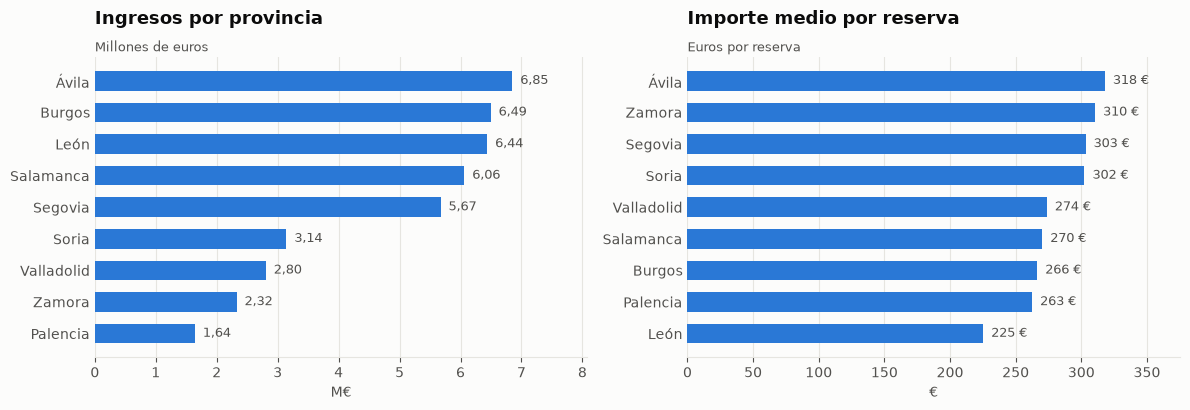

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
barh(q1["ingresos"] / 1e6, "Ingresos por provincia", "Millones de euros", xlabel="M€", dec=2, ax=axes[0])
barh(q1["importe_medio"], "Importe medio por reserva", "Euros por reserva", xlabel="€", dec=0, suffix=" €", ax=axes[1])
plt.tight_layout()
plt.show()

> **Ávila es la provincia que más factura, pero no la que más reservas tiene.** León tiene más reservas, 28.578 frente a 21.542, pero su reserva media es mucho más barata: 225 € frente a 318 €. Palencia y Zamora cierran la tabla en las dos medidas.

### 6.2 ¿Cómo evolucionan las reservas por mes y cuánto crecen de 2024 a 2025?

```sql
SELECT d.mes, d.nombre_mes,
       COUNT(*) FILTER (WHERE d.anio = 2024) AS reservas_2024,
       COUNT(*) FILTER (WHERE d.anio = 2025) AS reservas_2025
FROM dw.fact_reservas f JOIN dw.dim_fecha d USING (fecha_key)
GROUP BY d.mes, d.nombre_mes ORDER BY d.mes;
```

In [15]:
q2 = (
    reservas.pivot_table(index=["mes", "nombre_mes"], columns="anio", values="reserva_id", aggfunc="size")
    .rename(columns=lambda y: f"reservas_{y}")
    .assign(variacion_pct=lambda d: (d["reservas_2025"] / d["reservas_2024"] - 1) * 100)
    .reset_index("mes", drop=True)
)
q2

anio,reservas_2024,reservas_2025,variacion_pct
nombre_mes,,,
enero,3840,3946,"2,76"
febrero,3391,3484,"2,74"
marzo,5090,5075,"-0,29"
abril,6633,7283,"9,80"
mayo,6273,6692,"6,68"
junio,6596,6834,"3,61"
julio,8434,9138,"8,35"
agosto,10261,10663,"3,92"
septiembre,6597,6822,"3,41"


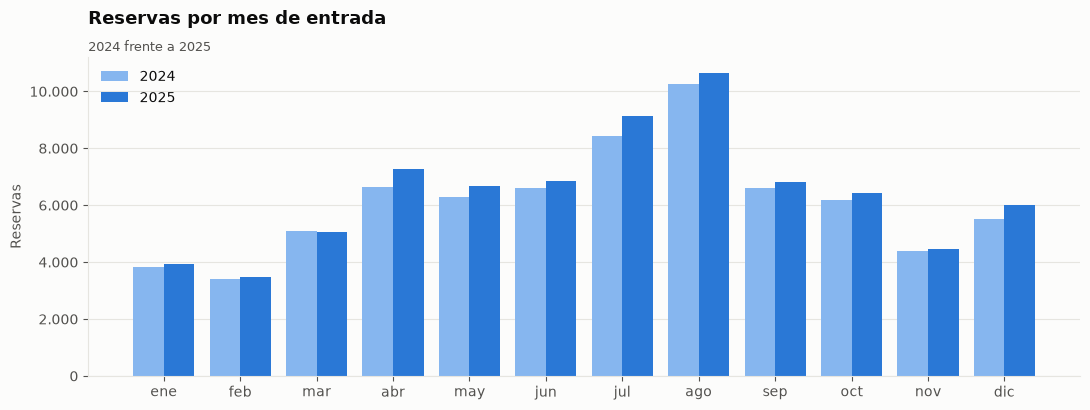

In [16]:
fig, ax = plt.subplots(figsize=(11, 4.2))
x = np.arange(len(q2))
ax.bar(x - 0.2, q2["reservas_2024"], width=0.4, color=ACCENT_LIGHT, label="2024")
ax.bar(x + 0.2, q2["reservas_2025"], width=0.4, color=ACCENT, label="2025")
ax.set_xticks(x, [m[:3] for m in q2.index])
_titles(ax, "Reservas por mes de entrada", "2024 frente a 2025")
ax.set_ylabel("Reservas")
ax.grid(axis="y", color=GRID, linewidth=0.8)
ax.set_axisbelow(True)
_axis_es(ax.yaxis)
ax.legend(frameon=False, loc="upper left")
plt.tight_layout()
plt.show()

> La curva es la de un destino de interior: **agosto es el pico**, con más de 10.000 reservas cada año, y **febrero el valle**. También destacan Semana Santa (abril) y el puente de diciembre. 2025 crece respecto a 2024 en 11 de los 12 meses. Solo marzo baja, un 0,3 %.

### 6.3 ¿Qué tipo de alojamiento factura más y cuál es su precio medio por persona y noche?

```sql
SELECT a.tipo_establecimiento, COUNT(*) AS reservas, SUM(f.importe_total) AS ingresos,
       ROUND(SUM(f.importe_total) / SUM(f.num_huespedes * f.num_noches), 2) AS precio_persona_noche
FROM dw.fact_reservas f JOIN dw.dim_alojamiento a USING (alojamiento_key)
GROUP BY a.tipo_establecimiento ORDER BY ingresos DESC;
```

In [17]:
q3 = (
    reservas.assign(pernoctaciones=lambda d: d["num_huespedes"] * d["num_noches"])
    .groupby("tipo_establecimiento")
    .agg(reservas=("reserva_id", "size"), ingresos=("importe_total", "sum"),
         pernoctaciones=("pernoctaciones", "sum"), huespedes_medios=("num_huespedes", "mean"),
         noches_medias=("num_noches", "mean"))
    .assign(precio_persona_noche=lambda d: d["ingresos"] / d["pernoctaciones"])
    .sort_values("ingresos", ascending=False)
)
q3

,reservas,ingresos,pernoctaciones,huespedes_medios,noches_medias,precio_persona_noche
tipo_establecimiento,,,,,,
Alojam. Turismo Rural,33889,"16.658.355,71",382066,"3,66","3,09","43,60"
Vivienda turística,36413,"11.185.172,70",333392,"2,90","3,16","33,55"
Alojamientos Hoteleros,45164,"9.355.419,10",181425,"2,00","2,01","51,57"
Campings,15761,"2.074.993,47",142098,"2,71","3,34","14,60"
Apartamentos Turísticos,8989,"1.873.583,03",62417,"2,33","2,98","30,02"
Albergues,9784,"275.697,86",19748,"1,76","1,15","13,96"


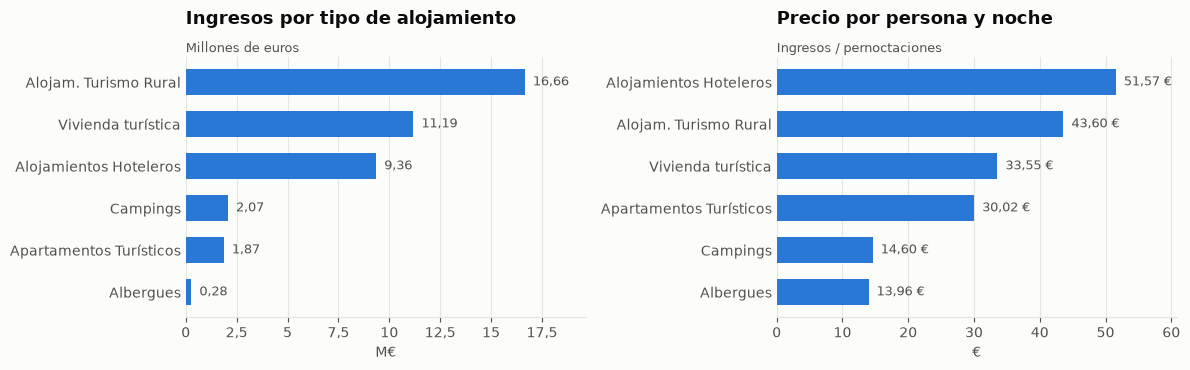

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
barh(q3["ingresos"] / 1e6, "Ingresos por tipo de alojamiento", "Millones de euros", xlabel="M€", dec=2, ax=axes[0])
barh(q3["precio_persona_noche"], "Precio por persona y noche", "Ingresos / pernoctaciones", xlabel="€",
     dec=2, suffix=" €", ax=axes[1])
plt.tight_layout()
plt.show()

> El **turismo rural es el que más ingresa**, 16,7 M€, aunque tiene menos reservas que los hoteles. Sus grupos son más grandes (3,7 huéspedes de media frente a 2,0) y sus estancias, más largas. El **hotel es el más caro por persona y noche**, con 51,57 €, y campings y albergues los más baratos, por debajo de 15 €.

### 6.4 ¿Qué canales se usan más y cuánto se paga en comisiones a intermediarios?

```sql
SELECT c.canal, c.tipo_canal, COUNT(*) AS reservas,
       ROUND(100.0 * COUNT(*) / SUM(COUNT(*)) OVER (), 1) AS pct_reservas,
       ROUND(SUM(f.importe_total * c.comision_pct / 100), 2) AS comisiones
FROM dw.fact_reservas f JOIN dw.dim_canal c USING (canal_key)
GROUP BY c.canal, c.tipo_canal ORDER BY reservas DESC;
```

In [19]:
q4 = (
    reservas.assign(comision=lambda d: d["importe_total"] * d["comision_pct"] / 100)
    .groupby(["canal", "tipo_canal"])
    .agg(reservas=("reserva_id", "size"), comisiones=("comision", "sum"))
    .assign(pct_reservas=lambda d: d["reservas"] / d["reservas"].sum() * 100)
    .sort_values("reservas", ascending=False)
    [["reservas", "pct_reservas", "comisiones"]]
)
q4

,,reservas,pct_reservas,comisiones
canal,tipo_canal,,,
Plataforma online (OTA),Intermediado,65799,"43,87","2.790.806,06"
Web propia,Directo,36657,"24,44","0,00"
Teléfono / email,Directo,21954,"14,64","0,00"
Presencial,Directo,14084,"9,39","0,00"
Agencia de viajes,Intermediado,11506,"7,67","329.213,13"


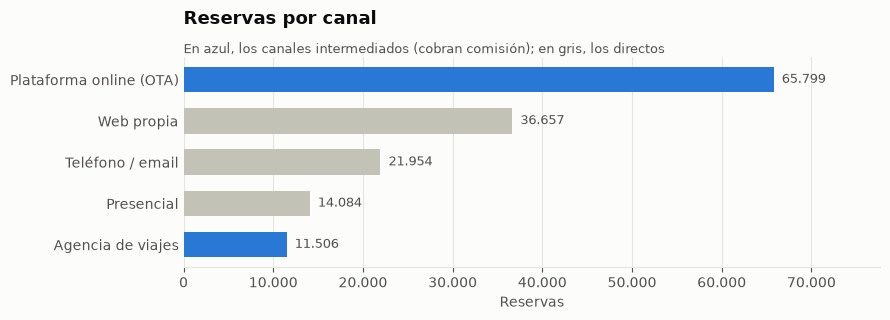

In [20]:
colores_canal = pd.Series({c: (NEUTRAL if t == "Directo" else ACCENT) for c, t in q4.index})
barh(q4["reservas"].droplevel("tipo_canal"), "Reservas por canal",
     "En azul, los canales intermediados (cobran comisión); en gris, los directos", colors=colores_canal)

> Las **OTA concentran el 43,9 % de las reservas** y casi **2,8 M€ en comisiones**. Con las agencias de viajes, los intermediarios se llevan más de 3,1 M€. Los tres canales directos suman el 48,5 % de las reservas y no pagan comisión.

### 6.5 ¿De dónde vienen los clientes y con cuánta antelación reservan?

```sql
SELECT p.mercado, p.origen, COUNT(*) AS reservas,
       ROUND(AVG(f.dias_antelacion), 1) AS antelacion_media_dias,
       ROUND(AVG(f.num_noches), 2) AS estancia_media
FROM dw.fact_reservas f JOIN dw.dim_procedencia p USING (procedencia_key)
GROUP BY p.mercado, p.origen ORDER BY reservas DESC;
```

In [21]:
q5 = (
    reservas.groupby(["mercado", "origen"])
    .agg(reservas=("reserva_id", "size"), antelacion_media_dias=("dias_antelacion", "mean"),
         estancia_media=("num_noches", "mean"))
    .sort_values("reservas", ascending=False)
)
q5

reservas  antelacion_media_dias  \
mercado       origen                                                  
Nacional      Comunidad de Madrid      32605                  17,67   
              Castilla y León          30011                   8,72   
              Resto de España          13247                  17,32   
              País Vasco               10457                  17,28   
              Cataluña                  8802                  17,77   
Internacional Francia                   7526                  45,91   
Nacional      Andalucía                 7378                  17,50   
Internacional Portugal                  5968                  45,33   
Nacional      Galicia                   5927                  18,07   
              Comunidad Valenciana      5822                  17,72   
              Asturias                  4504                  17,80   
Internacional Reino Unido               4382                  44,06   
              Alemania                  2977                  46,07   
              Italia                    2926                  45,66   
              Estados Unidos            2913                  44,06   
              Latinoamérica             2313                  44,42   
              Otros países              2242                  46,67   

                                    estancia_media  
mercado       origen                                
Nacional      Comunidad de Madrid             2,67  
              Castilla y León                 2,66  
              Resto de España                 2,69  
              País Vasco                      2,68  
              Cataluña                        2,68  
Internacional Francia                         2,68  
Nacional      Andalucía                       2,66  
Internacional Portugal                        2,65  
Nacional      Galicia                         2,68  
              Comunidad Valenciana            2,69  
              Asturias                        2,66  
Internacional Reino Unido                     2,71  
              Alemania                        2,69  
              Italia                          2,68  
              Estados Unidos                  2,70  
              Latinoamérica                   2,65  
              Otros países                    2,69

In [22]:
# Roll-up de origen a mercado: la misma pregunta a un nivel más agregado
reservas.groupby("mercado").agg(
    reservas=("reserva_id", "size"),
    pct_reservas=("reserva_id", lambda s: len(s) / len(reservas) * 100),
    antelacion_media_dias=("dias_antelacion", "mean"),
    estancia_media=("num_noches", "mean"),
)

,reservas,pct_reservas,antelacion_media_dias,estancia_media
mercado,,,,
Internacional,31247,"20,83","45,31","2,68"
Nacional,118753,"79,17","15,36","2,67"


> El roll-up de origen a mercado deja ver el patrón con claridad: **el cliente internacional reserva con unos 45 días de antelación, el nacional con unos 15**. La estancia media es casi igual en ambos, unas 2,7 noches. Madrid y la propia Castilla y León son los orígenes principales, y el cliente de Castilla y León es el que menos se anticipa: menos de 9 días.

### 6.6 ¿Qué municipios reciben más reservas y cuánto patrimonio tienen?

```sql
SELECT m.municipio, m.provincia, m.num_monumentos, m.num_oficinas_turismo,
       COUNT(*) AS reservas, SUM(f.num_huespedes) AS huespedes
FROM dw.fact_reservas f JOIN dw.dim_municipio m USING (municipio_key)
GROUP BY m.municipio, m.provincia, m.num_monumentos, m.num_oficinas_turismo
ORDER BY reservas DESC LIMIT 10;
```

In [23]:
q6 = (
    reservas.groupby(["municipio", "provincia", "num_monumentos", "num_oficinas_turismo"])
    .agg(reservas=("reserva_id", "size"), huespedes=("num_huespedes", "sum"))
    .sort_values("reservas", ascending=False)
    .head(10)
    .reset_index()
)
q6

,municipio,provincia,num_monumentos,num_oficinas_turismo,reservas,huespedes
0,SALAMANCA,Salamanca,45,1,6977,15592
1,LEÓN,León,25,1,6476,15311
2,BURGOS,Burgos,30,2,6174,14525
3,VALLADOLID,Valladolid,51,4,3478,7546
4,ÁVILA,Ávila,44,2,3072,7223
5,SEGOVIA,Segovia,46,2,3007,6720
6,PONFERRADA,León,11,1,1996,4762
7,SORIA,Soria,18,3,1982,4728
8,ZAMORA,Zamora,33,2,1792,4235
9,CANDELEDA,Ávila,4,1,1647,4604


> Las capitales históricas encabezan la lista: Salamanca, León y Burgos. Pero **más patrimonio no significa más reservas**. Valladolid tiene el mayor número de monumentos, 51, y recibe la mitad de reservas que Salamanca. Tener el patrimonio como atributo de `dim_municipio` es lo que permite plantear esta pregunta sin añadir otra dimensión.

### 6.7 ¿Se reserva más en fin de semana, en festivos y en temporada alta? ¿Cambia el importe?

Una temporada puede tener más reservas simplemente porque tiene más días. Por eso se mide en **reservas por día**.

```sql
SELECT d.temporada, d.es_fin_de_semana, d.es_festivo, COUNT(*) AS reservas,
       ROUND(COUNT(*)::numeric / COUNT(DISTINCT d.fecha), 1) AS reservas_por_dia,
       ROUND(AVG(f.importe_total), 2) AS importe_medio
FROM dw.fact_reservas f JOIN dw.dim_fecha d USING (fecha_key)
GROUP BY d.temporada, d.es_fin_de_semana, d.es_festivo
ORDER BY d.temporada, d.es_fin_de_semana, d.es_festivo;
```

In [24]:
q7 = (
    reservas.groupby(["temporada", "es_fin_de_semana", "es_festivo"])
    .agg(reservas=("reserva_id", "size"), dias=("fecha", "nunique"), importe_medio=("importe_total", "mean"))
    .assign(reservas_por_dia=lambda d: d["reservas"] / d["dias"])
    [["reservas", "dias", "reservas_por_dia", "importe_medio"]]
)
q7

reservas  dias  reservas_por_dia  \
temporada es_fin_de_semana es_festivo                                     
Alta      False            False          29353   111            264,44   
                           True            4004    12            333,67   
          True             False          13702    48            285,46   
                           True             221     1            221,00   
Baja      False            False          25452   183            139,08   
          True             False          11391    75            151,88   
Media     False            False          44351   210            211,20   
                           True            2104     7            300,57   
          True             False          18422    81            227,43   
                           True            1000     3            333,33   

                                       importe_medio  
temporada es_fin_de_semana es_festivo                 
Alta      False            False              358,80  
                           True               322,07  
          True             False              384,39  
                           True               308,70  
Baja      False            False              207,48  
          True             False              229,71  
Media     False            False              241,79  
                           True               245,29  
          True             False              264,33  
                           True               259,82

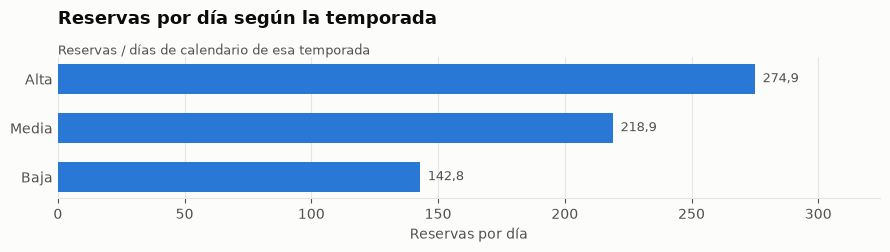

In [25]:
por_temporada = (
    reservas.groupby("temporada")
    .agg(reservas=("reserva_id", "size"), dias=("fecha", "nunique"))
    .assign(reservas_por_dia=lambda d: d["reservas"] / d["dias"])
    .reindex(["Alta", "Media", "Baja"])
)
barh(por_temporada["reservas_por_dia"], "Reservas por día según la temporada",
     "Reservas / días de calendario de esa temporada", xlabel="Reservas por día", dec=1)

> En **reservas por día**, la temporada alta casi duplica a la baja: 275 frente a 143. Los fines de semana y los festivos suben la actividad en todas las temporadas. El **importe medio también es mayor en temporada alta**, con 359 € en un día laborable, frente a 207 € en temporada baja. Algunas combinaciones tienen muy pocos días, como el único festivo en fin de semana de la temporada alta, así que sus medias son poco estables.

<a id="summary"></a>
## 7. Conclusiones

- **Fuentes (actividad 1):** son cuatro catálogos unidos por `cod_ine`. Hay una sorpresa en las claves: `n_registro` no es único y la clave natural del alojamiento es `(tipo_establecimiento, n_registro)`. Las oficinas no tienen identificador fiable.
- **Hecho y dimensiones (actividad 2):** el hecho son las reservas, con grano de una fila por reserva. Hay cinco dimensiones: fecha, alojamiento, municipio, canal y procedencia. Monumentos y oficinas entran como atributos del municipio, porque una reserva no se asocia a un monumento.
- **Esquema (actividad 3):** es una estrella pura. Todas las dimensiones tienen claves sustitutas, ninguna clave foránea queda huérfana y el precio por persona y noche se calcula en cada consulta en lugar de guardarse.
- **Consultas (actividad 6):** las siete preguntas se resuelven con el mismo patrón de *star join* + `GROUP BY`. Los resultados coinciden con los de `sql/05_dw_queries.sql` en PostgreSQL.

> Los datos de reservas son **ficticios**: sirven para validar el modelo y las consultas, no para sacar conclusiones reales sobre el turismo en Castilla y León.